# Podstawy AI – Sterownik wentylatora w języku FCL

**FCL** (*Fuzzy Control Language*, norma IEC 61131-7) to standardowy, tekstowy format opisu sterowników rozmytych, używany w przemyśle. Plik FCL zawiera wszystko, co sterownik wie: zmienne, funkcje przynależności, reguły i ustawienia operatorów.

**Potrzebne pliki** (w tym samym folderze co notebook; w Google Colab: ikona folderu po lewej → „Prześlij”):
- `wentylator.fcl` – sterownik do analizy,
- `fcl_narzedzie.py` – narzędzie, które czyta pliki FCL i liczy wynik.

Nic nie trzeba instalować – narzędzie używa tylko `numpy` i `matplotlib`, które są w Colab.

**Plan:**
1. Analiza pliku FCL (A–C)
2. Dodanie stanu `very_hot` i nowej reguły
3. Testy sterownika
4. Trzy konfiguracje: implikacja, wyostrzanie, suma zbiorów
5. Ocena sterownika
6. Drugie wejście: wilgotność

**Do oddania:** pliki FCL (co najmniej 3 konfiguracje i wersja z wilgotnością) oraz ten notebook zapisany jako PDF (Plik → Drukuj → Zapisz jako PDF).

In [ ]:
from fcl_narzedzie import wynik, tabela, rysuj_zbiory, krzywa, wariant, rozszerz, krzywe
print(open("wentylator.fcl", encoding="utf-8").read())

(* Podstawy AI – sterownik rozmyty wentylatora
   Jedno wejście: temperatura, jedno wyjście: prędkość wentylatora. *)

FUNCTION_BLOCK wentylator

VAR_INPUT
    temperature : REAL;     (* temperatura w pomieszczeniu [°C] *)
END_VAR

VAR_OUTPUT
    fan_speed : REAL;       (* prędkość wentylatora [% mocy] *)
END_VAR

FUZZIFY temperature
    RANGE := (0 .. 40);
    TERM cold := (0, 1) (10, 1) (20, 0);
    TERM warm := (10, 0) (20, 1) (30, 0);
    TERM hot  := (20, 0) (30, 1) (40, 1);
END_FUZZIFY

DEFUZZIFY fan_speed
    RANGE := (0 .. 100);
    TERM low     := (0, 1) (20, 1) (45, 0);
    TERM medium  := (25, 0) (50, 1) (75, 0);
    TERM high    := (55, 0) (80, 1) (95, 0);
    TERM maximum := (85, 0) (100, 1);
    METHOD : COG;           (* wyostrzanie: środek ciężkości *)
    DEFAULT := 0;           (* wynik, gdy żadna reguła nie działa *)
END_DEFUZZIFY

RULEBLOCK reguly
    AND  : MIN;             (* "i" w części JEŚLI *)
    ACT  : MIN;             (* implikacja: MIN przycina, PROD skalu

---
## 1. Analiza pliku FCL

Plik składa się z bloków. Każdy odpowiada jednemu krokowi sterownika rozmytego:

| blok | co zawiera |
|---|---|
| `VAR_INPUT` / `VAR_OUTPUT` | nazwy wejść i wyjść |
| `FUZZIFY` | funkcje przynależności wejścia, zapisane punktami `(x, μ)` – łamana przez te punkty |
| `DEFUZZIFY` | funkcje przynależności wyjścia, metoda wyostrzania `METHOD`, wartość `DEFAULT` |
| `RULEBLOCK` | operatory (`AND`, `ACT` – implikacja, `ACCU` – suma zbiorów) i reguły `IF … THEN …` |

Przykład: `TERM cold := (0, 1) (10, 1) (20, 0);` znaczy: do 10 °C „zimno” w stopniu 1, potem stopień maleje liniowo do 0 przy 20 °C.

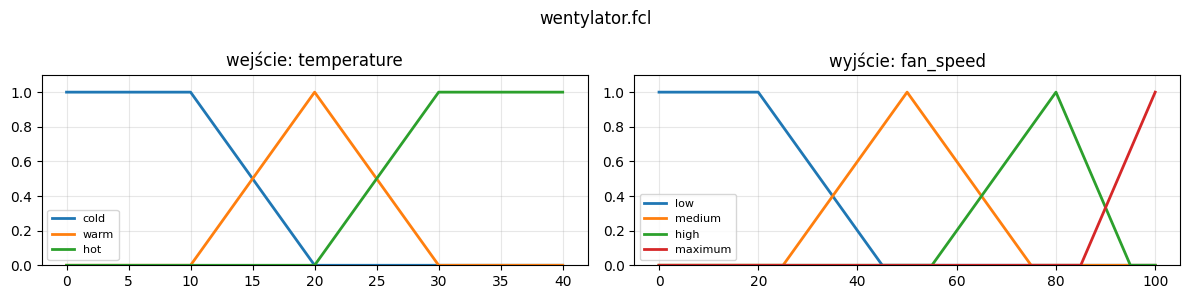

In [ ]:
rysuj_zbiory("wentylator.fcl")

**Zadanie 1A.** Wypisz zmienne wejściowe i wyjściowe (nazwa, zakres, jednostka).

**Zadanie 1B.** Wypisz funkcje przynależności każdej zmiennej i opisz słowami, co znaczą (np. „cold – do 10 °C na pewno zimno, od 20 °C na pewno nie”).

**Zadanie 1C.** Wypisz reguły i opisz jednym zdaniem, jak działa ten sterownik.

*Twoja odpowiedź:*

---
1A. Sterownik na wejściu otrzymuje wyłącznie pomiar temperatury, z zakresu od 0°C do 40°C oraz posiada wyłącznie jedno wyjściu odpowiadające za prędkość wirnika wentylatora, z zakresu od 0 do 100.



---
1B. Sterownik posiada trzy funkcje dla temperatury przynależności dla dla zmiennych lingwistycznych cold, warm, hot, które odpowiednio odpowiadają przedziałom w trójkątnej funkcji przynależności (0, 10, 20), (10, 20 ,30), (20,30, 40). Do wyjaśnienia opisu z treści zadania należy zauważyć, że przynależności, w niektórych miejscach zupełnie się nie pokrywają.Dlatego mówiąc, że przy 10°C jest na pewno zimno ponieważ, żadna inna funkcja przynależności nie przybiera wartości w tym zakresie, również dla 20°C wyłacznie wyłącznie warm rozpatrzuje ten zakres, więc mozna powiedzieć, że dla cold 20°C przyjmuje wartość 0, czyli na pewno nie.

Dalej sterownik posiada również 4 funkcje dla prędkości wirnika wentylatora o zmiennych low, medium, high, maximum, które odpowiadają jak w przypadku temperatury odpowiednio przedziałom (0, 20, 45), (25, 50, 75), (65, 80, 95), (85, 100)

---
1C. Reguły takiego wentylatora wyglądają następująco, gdy jest cold, wentylator kręci się wolno, gdy jest warm, kręci się średnio, a gdy jest hot, kręci się szybko. Następnie sterownik sprawdza, w jakim stopniu temperatura jest zimna, ciepła i gorąca. Każda reguła przycina swój stan prędkości do tego stopnia, przycięte kształty łączy się w jeden w postaci sumy dwóch zbiorów, najwyższa wartość takiej sumy zbiorów dla odpowiedniej temperautry to wartość, z jaką powinien kręcić się wirnik wentylatora.

---
## 2. Dodanie stanu `very_hot`

Komórka poniżej zapisuje plik `wentylator_k1.fcl`. Na start zawiera kopię oryginału. Zmień go bezpośrednio w komórce:

1. **(A)** Dodaj do `temperature` stan `very_hot`. Pamiętaj, że `hot` i `very_hot` muszą się **nakładać**, a `hot` powinien przestać być płaski do 40 °C (inaczej przy 40 °C będzie jednocześnie w pełni „hot” i „very_hot”).
2. **(B)** Dodaj regułę: jeśli `very_hot`, to `fan_speed` = `maximum`.

Uruchom komórkę – zapisze plik. Potem uruchom następną, żeby zobaczyć wykres.

In [ ]:
%%writefile wentylator_k1.fcl
(* TODO: dodaj stan very_hot i regułę dla niego *)

FUNCTION_BLOCK wentylator

VAR_INPUT
    temperature : REAL;     (* temperatura w pomieszczeniu [°C] *)
END_VAR

VAR_OUTPUT
    fan_speed : REAL;       (* prędkość wentylatora [% mocy] *)
END_VAR

FUZZIFY temperature
    RANGE := (0 .. 40);
    TERM cold := (0, 1) (10, 1) (20, 0);
    TERM warm := (10, 0) (20, 1) (30, 0);
    TERM hot  := (20, 0) (30, 1) (40, 0);
    TERM very_hot := (30, 0) (40, 1);
END_FUZZIFY

DEFUZZIFY fan_speed
    RANGE := (0 .. 100);
    TERM low     := (0, 1) (20, 1) (45, 0);
    TERM medium  := (25, 0) (50, 1) (75, 0);
    TERM high    := (55, 0) (80, 1) (95, 0);
    TERM maximum := (85, 0) (100, 1);
    METHOD : COG;           (* wyostrzanie: środek ciężkości *)
    DEFAULT := 0;           (* wynik, gdy żadna reguła nie działa *)
END_DEFUZZIFY

RULEBLOCK reguly
    AND  : MIN;             (* "i" w części JEŚLI *)
    ACT  : MIN;             (* implikacja: MIN przycina, PROD skaluje *)
    ACCU : MAX;             (* suma zbiorów na wyjściu: MAX, BSUM *)

    RULE 1 : IF temperature IS cold     THEN fan_speed IS low;
    RULE 2 : IF temperature IS warm     THEN fan_speed IS medium;
    RULE 3 : IF temperature IS hot      THEN fan_speed IS high;
    RULE 4 : IF temperature IS very_hot THEN fan_speed IS maximum;
END_RULEBLOCK

END_FUNCTION_BLOCK

Overwriting wentylator_k1.fcl


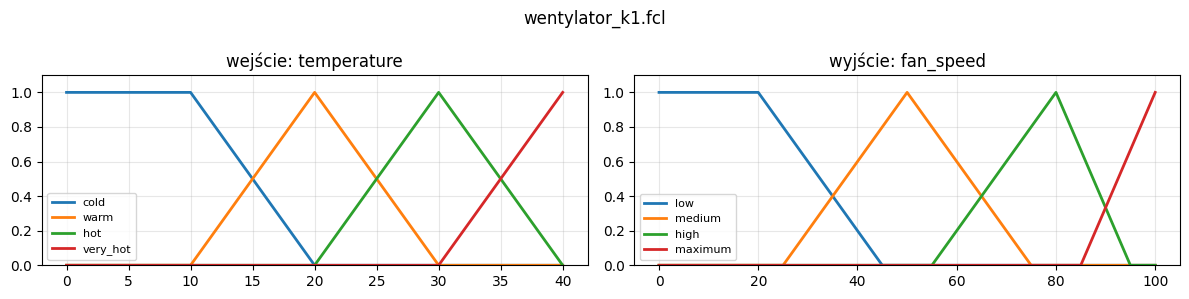

In [ ]:
rysuj_zbiory("wentylator_k1.fcl")

---
## 3. Testy sterownika

**Zadanie 2C.** Porównaj oryginał i Twoją wersję dla temperatur od 0 do 40 °C co 5 stopni. Wykres pokazuje prędkość dla wszystkich temperatur naraz.

 temperature  wentylator  wentylator_k1
           0       17.03          17.03
           5       17.03          17.03
          10       17.03          17.03
          15       34.44          34.44
          20       50.00          50.00
          25       61.15          61.15
          30       76.67          76.67
          35       76.67          80.27
          40       76.67          95.03


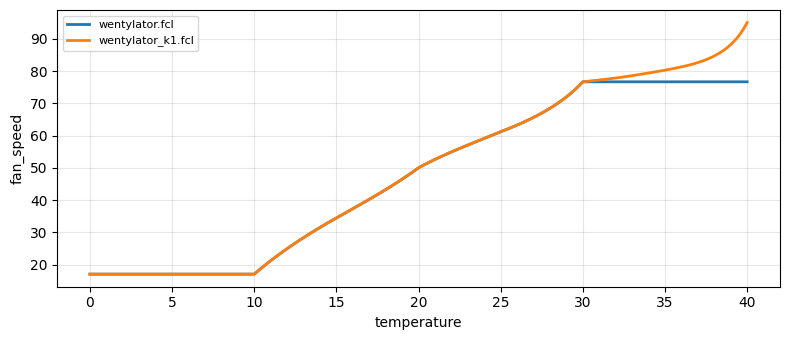

In [ ]:
TEMPERATURY = [0, 5, 10, 15, 20, 25, 30, 35, 40]
tabela(["wentylator.fcl", "wentylator_k1.fcl"], "temperature", TEMPERATURY)
krzywa(["wentylator.fcl", "wentylator_k1.fcl"], "temperature")

**Pytanie 3a.** Co robi oryginalny sterownik powyżej 30 °C? Co zmieniło dodanie `very_hot`?

**Pytanie 3b.** Jaką prędkość daje sterownik przy 0 °C, a jaką przy 40 °C? Czy wentylator kiedykolwiek się wyłącza albo osiąga 100%? Dlaczego?

*Twoja odpowiedź:*

---
 3A. Oryginalny sterownik powyżej 30°C nie zmienia prędkości wentylatora poniewż nie posiada dodatkowej reguły odpowiadającej za funkcje przynależności maximum w prędkości wirnika wentylatora. Dopiero po dodaniu funkcji lepszej fukncji przynależności opisującej temperature very_hot oraz regułę obsługującą tę funkcje otrzymujemy dostęp do najwyższych prędkości wentylatora.

---
3B. Z wykresu oraz z tabeli wynika, że przy skrajnych temperaturach 0°C wirnik wentylatora nadaj podtrzymuje pewne obroty równe prędkości ok. 17, natomiast dla temperatury 40°C w obu przypadkach nie nigdy nie osiągają predkości na poziomie 100. Domyślam się, że jest to metodę wyostrania zadeklarowaną w obu FCL.

---
## 4. Trzy konfiguracje

**Zadanie 3A.** Przetestuj sterownik z innymi ustawieniami. Każda konfiguracja to osobny plik FCL, w którym zmieniasz **jedną** rzecz:

| ustawienie w FCL | co określa | wariant do sprawdzenia |
|---|---|---|
| `ACT` | implikacja: jak siła reguły zmienia jej wniosek | `PROD` zamiast `MIN` |
| `METHOD` | wyostrzanie: jak z kształtu zrobić jedną liczbę | `MM` (środek maksimum) zamiast `COG` |
| `ACCU` | suma zbiorów na wyjściu: jak łączyć wnioski reguł | `BSUM` (suma ograniczona) zamiast `MAX` |

Funkcja `wariant` tworzy kopię pliku ze zmienionym ustawieniem. Możesz też skopiować plik ręcznie i zmienić jedną linijkę.

Zapisano wentylator_k2.fcl: ACT = PROD
Zapisano wentylator_k3.fcl: METHOD = MM
Zapisano wentylator_k4.fcl: ACCU = BSUM
 temperature  wentylator_k1  wentylator_k2  wentylator_k3  wentylator_k4
           0          17.03          17.03          10.00          17.03
           5          17.03          17.03          10.00          17.03
          10          17.03          17.03          10.00          17.03
          15          34.44          31.08          30.93          34.50
          20          50.00          50.00          50.00          50.00
          25          61.15          61.54          62.23          61.60
          30          76.67          76.67          80.00          76.67
          35          80.27          81.17          82.64          81.06
          40          95.03          95.03         100.00          95.03
          28          68.45          70.79          79.00          68.08
          32          77.84          77.85          79.00          78.62
     

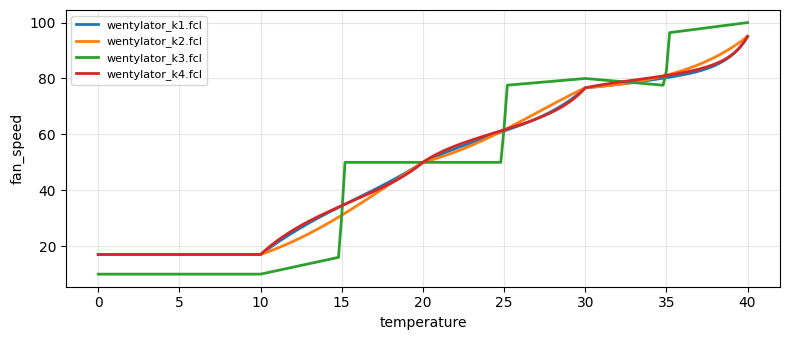

In [ ]:
# TODO: utwórz trzy konfiguracje (po jednej zmianie każda)
k2 = wariant("wentylator_k1.fcl", "wentylator_k2.fcl", ACT="PROD")
# k3 = wariant(...)
k3 = wariant("wentylator_k1.fcl", "wentylator_k3.fcl", METHOD="MM")
# k4 = wariant(...)
k4 = wariant("wentylator_k1.fcl", "wentylator_k4.fcl", ACCU="BSUM")

KONFIGURACJE = ["wentylator_k1.fcl", k2, k3, k4]   # TODO: dopisz k3 i k4
tabela(KONFIGURACJE, "temperature", TEMPERATURY + [28, 32, 34])
krzywa(KONFIGURACJE, "temperature")

**Zadanie 3A (opis).** Dla każdej konfiguracji opisz: co zmieniłeś, przy jakich temperaturach wynik się zmienił i o ile. Która zmiana ma największy wpływ?

*Twoja odpowiedź:*

---
3A.
*   Konfiguracja k2. Została zmieniona implikację ACT z MIN na PROD, która skaluję reguły. W wyniku przejścia pomiędzy prędkościami wydają się najbardziej liniowe i płynne.
*   Konfiguracja k3. Została zmieniona metoda wyostrzenia METHOD z COG na MM. Wynik zmienia się prawie wszędzie i jest najbardziej widoczny z pośród wszystkich konfiguracji sterownika. Przejścia pomiędzy prędkościami stały się bardzo schodkowe, a nawet nieproporcjonalne do zmiany w temperaturze.
*   Konfiguracja k4. Został zmieniony sposób sumowania zbiorów na wejściu ACCU z MAX na BSUM. Zmiany są bardzo subtelne i mało widoczne wględem konfiguracji k1.

---
## 5. Ocena sterownika

**Zadanie 3B.** Jak oceniasz działanie sterownika? Odnieś się do:
- czy prędkość rośnie z temperaturą płynnie, czy skokami,
- czy zakres prędkości (najmniejsza i największa) jest sensowny dla wentylatora,
- którą konfigurację wybrałbyś do prawdziwego urządzenia i dlaczego.

*Twoja odpowiedź:*

---
3B. Oryginalny sterownik z dodaną funkcją przynależności very-hot działa płynnie. Prędkość rośnie razem z temperaturą bez skoków i nigdy nie maleje poniżej pewnej wartości obrotów co jest pewnym porządanym efektem przy wentylatorach, również można powiedzieć, że nieosiąganie maksymalnych obrotów też jest pewnym plusem. Jednak z pośród wszystkich konfiguracji najbarzdiej sensowna wydaje się konfiguracja k2 , która daje najrówniejszy wzrost prędkości względem temperatury. Konfigurajce k3 odrzuciłbym na pierwszym miejsciu, ponieważ dla tego zastosowania skokowe wzrosty prędkości są nieporządanym efektem.

---
## 6. Drugie wejście: wilgotność

Przy wysokiej wilgotności to samo ciepło jest bardziej uciążliwe, więc wentylator powinien kręcić się szybciej. Dodajemy do Twojego sterownika z części 2 drugie wejście `humidity` (wilgotność powietrza, 0–100%).

### 6.1 Rozszerzenie pliku

Nie musisz przepisywać całego pliku. Funkcja `rozszerz` bierze `wentylator_k1.fcl` i wkleja we właściwe miejsca trzy fragmenty, które piszesz w FCL:
1. nowe wejście w `VAR_INPUT` (gotowe),
2. blok `FUZZIFY humidity` z trzema stanami: `dry`, `normal`, `humid`,
3. co najmniej dwie nowe reguły, np. „ciepło **i** wilgotno → szybko”, „gorąco **i** wilgotno → maksimum”.

Zapisano wentylator_h.fcl – plik wczytuje się poprawnie.


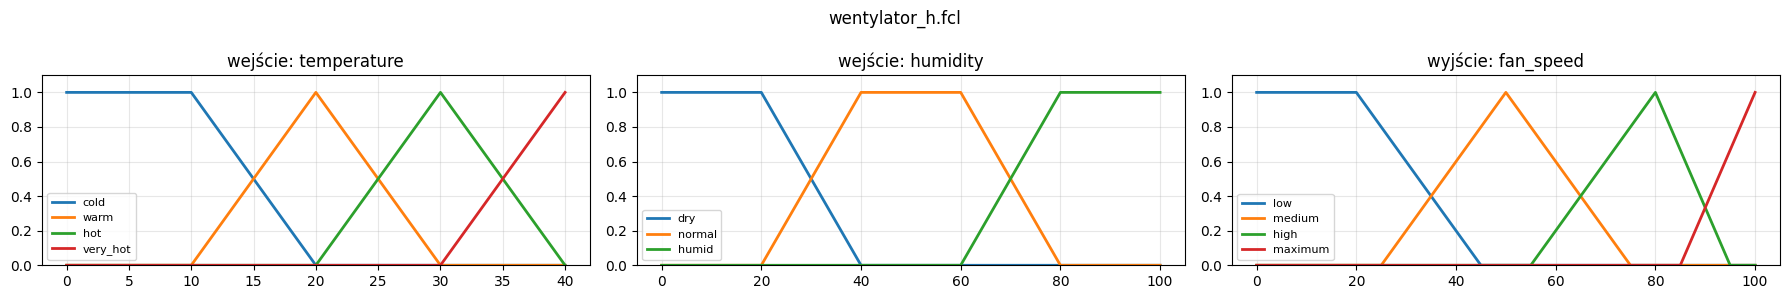

In [ ]:
NOWE_WEJSCIE = "humidity : REAL;     (* wilgotność [%] *)"

# TODO: uzupełnij punkty (x, μ) – sąsiednie stany muszą się nakładać
NOWY_FUZZIFY = """
FUZZIFY humidity
    RANGE := (0 .. 100);
    TERM dry    := (0, 1) (20, 1) (40, 0);
    TERM normal := (20, 0) (40, 1) (60, 1) (80, 0);
    TERM humid  := (60, 0) (80, 1) (100, 1);
END_FUZZIFY
"""

# TODO: dopisz co najmniej dwie reguły z humidity (numeruj dalej: RULE 5, RULE 6, ...)
NOWE_REGULY = """
RULE 5 : IF temperature IS warm AND humidity IS humid THEN fan_speed IS high;
RULE 6 : IF temperature IS hot AND humidity IS humid THEN fan_speed IS maximum;
"""

rozszerz("wentylator_k1.fcl", "wentylator_h.fcl",
         wejscie=NOWE_WEJSCIE, fuzzify=NOWY_FUZZIFY, reguly=NOWE_REGULY)
rysuj_zbiory("wentylator_h.fcl")

**Testy.** Ta sama temperatura przy suchym (20%) i wilgotnym (90%) powietrzu, a potem wilgotność od 0 do 100% przy stałych 25 °C.

Powietrze suche (humidity = 20):
 temperature  wentylator_h
           0         17.03
           5         17.03
          10         17.03
          15         34.44
          20         50.00
          25         61.15
          30         76.67
          35         80.27
          40         95.03

Powietrze wilgotne (humidity = 90):
 temperature  wentylator_h
           0         17.03
           5         17.03
          10         17.03
          15         45.58
          20         61.54
          25         65.26
          30         81.17
          35         80.27
          40         95.03

Stała temperatura 25 °C:
    humidity  wentylator_h
           0         61.15
          20         61.15
          40         61.15
          60         61.15
          75         65.26
          90         65.26
         100         65.26


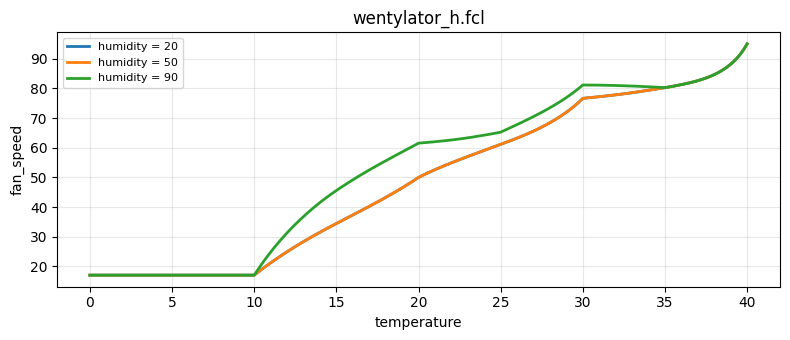

In [ ]:
print("Powietrze suche (humidity = 20):")
tabela("wentylator_h.fcl", "temperature", TEMPERATURY, humidity=20)
print("\nPowietrze wilgotne (humidity = 90):")
tabela("wentylator_h.fcl", "temperature", TEMPERATURY, humidity=90)
print("\nStała temperatura 25 °C:")
tabela("wentylator_h.fcl", "humidity", [0, 20, 40, 60, 75, 90, 100], temperature=25)
krzywe("wentylator_h.fcl", "temperature", "humidity", [20, 50, 90])

**Pytanie 6a.** O ile wilgotne powietrze zwiększa prędkość przy 25 °C? Czy to dużo, czy mało?

**Pytanie 6b.** Czy wilgotność cokolwiek zmienia przy 10 °C? Dlaczego?

**Pytanie 6c.** Reguła 2 („warm → medium”) nic nie wie o wilgotności. Co robi, gdy powietrze jest wilgotne? Jak to wpływa na wynik z pytania 6a?

*Twoja odpowiedź:*

---
6A. Pomiar wykazał, że przy suchym powietrzu oraz temperaturze 25°C, sterownik obraca wirnik z prędkością 61,15. Natomiast przy tej samej temperaturze z powietrzem o wilgotnosci wynoszącej 90, obraca wirniki z prędkością 65,25. Różnica pomiędzy prędkościami, przy tej temperaturze nie jest znacząca, pomimo tego, że wilgotności są praktycznie w swoich skrajnych wartościach.

---
6B. Pomiary prędkości wirników przy temperaturze 10°C nie wykazały żądnych zmian w prędkości niezależnie od wilgotności powietrza. Jest to spowodowane tym, że w nowo dodanych regułach 5 i 6 rozpatrywane są wyłącznie temperatury wchodzące w skład zmiennych lingwistycznych warm i hot. Natomiast temperatura 10°C zalicza się w wylacznie do temperatury cold, dla której wilgotność nie zmienia prędkości.

---
6C. Na regułe 2 nie wpływa, odczytana przez sterownik, wilgotność powietrza. Temperatura 25°C zalicza się do Reguły 2, która przypisuje do niej predkość wentylatora medium, natomiast Reguła 5 przypisuje dla temperatury warm prędkość high. Przez powstały konflikt prędkość pracy wirnika jest zaniżona przez Regułe 2.

### 6.2 Poprawka: stare reguły tylko dla niewilgotnego powietrza

Zmień reguły 2 i 3 tak, żeby działały tylko, gdy powietrze **nie** jest wilgotne. FCL ma do tego słowo `NOT`:

`RULE 2 : IF temperature IS warm AND humidity IS NOT humid THEN fan_speed IS medium;`

Komórka poniżej robi kopię pliku i zamienia w niej tekst reguł.

Stała temperatura 25 °C:
    humidity  wentylator_h  wentylator_h2
           0         61.15          61.15
          20         61.15          61.15
          40         61.15          61.15
          60         61.15          61.15
          75         65.26          69.75
          90         65.26          80.27
         100         65.26          80.27


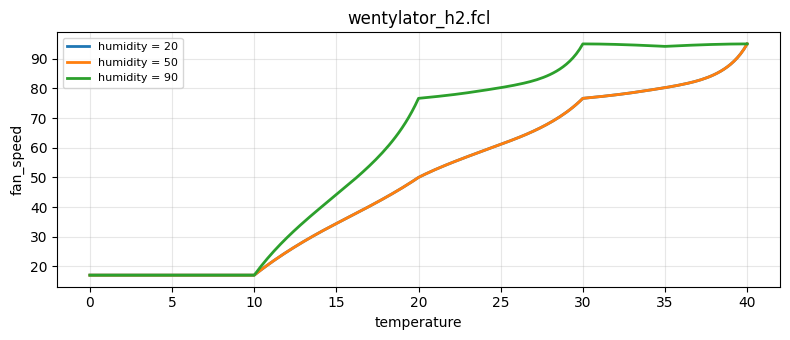

In [ ]:
tekst = open("wentylator_h.fcl", encoding="utf-8").read()
# TODO: zamień reguły 2 i 3 (tekst przed zamianą musi być DOKŁADNIE taki jak w Twoim pliku)
tekst = tekst.replace("RULE 2 : IF temperature IS warm     THEN fan_speed IS medium;",
                      "RULE 2 : IF temperature IS warm AND humidity IS NOT humid THEN fan_speed IS medium;")
tekst = tekst.replace("RULE 3 : IF temperature IS hot      THEN fan_speed IS high;",
                      "RULE 3 : IF temperature IS hot AND humidity IS NOT humid THEN fan_speed IS high;")
open("wentylator_h2.fcl", "w", encoding="utf-8").write(tekst)

print("Stała temperatura 25 °C:")
tabela(["wentylator_h.fcl", "wentylator_h2.fcl"], "humidity", [0, 20, 40, 60, 75, 90, 100], temperature=25)
krzywe("wentylator_h2.fcl", "temperature", "humidity", [20, 50, 90])

**Pytanie 6d.** Jak zmienił się wynik przy 25 °C i wilgotności 90% po poprawce? Dlaczego?

**Pytanie 6e.** Pełna baza reguł dla 4 stanów temperatury i 3 stanów wilgotności ma 4 × 3 = 12 reguł. Ile reguł ma Twój sterownik? Czy przy dwóch wejściach logika rozmyta daje coś, czego nie dałaby zwykła funkcja temperatury?

*Twoja odpowiedź:*

---
6D. Wykres pokazuje, że prędkość obrotu wirników wentylatora znacznie zwiększyła się, względem starych reguł 2 oraz 3. Dzieje się tak dlatego, że przez uaktualnienie tych reguł, przestają one działać dla wilgotności powietrza uznanej przez zmienną lingwistyczną za humid. A więc nic nie zaniża wartości reguł 5 oraz 6.

---
6E. Mój sterownik posiada dokładnie taką samą ilość reguł temperatury oraz wilgotności powietrza. Logika rozmyta, może się sprawdzić lepiej w sytuacjach, w których działanie zależy od wszystkich wejść naraz. Dlatego w przypadku sterowmnika sterującego prędkością wirnika, zależną od dwóch wejść, zwykłą funkcja temperatury nie otrzymalibyśmy podobnej zależności na otoczenie.

---
## Do oddania

1. Pliki FCL: `wentylator_k1.fcl` (z `very_hot`) oraz co najmniej dwa warianty (`wentylator_k2.fcl`, `wentylator_k3.fcl`, …). W Colab: kliknij plik w panelu po lewej → „Pobierz”.
2. Pliki z wilgotnością: `wentylator_h.fcl` i `wentylator_h2.fcl`.
3. Ten notebook z wynikami i odpowiedziami zapisany jako PDF: Plik → Drukuj → Zapisz jako PDF.